In [3]:
!pip install -q transformers datasets rouge-score bert-score scikit-learn matplotlib

In [4]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


# Import libary

In [5]:
import math, random
import numpy as np
import tensorflow as tf
import os
import json
from tensorflow.keras import layers, Model
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from transformers import GPT2TokenizerFast
from datasets import load_dataset
from rouge_score import rouge_scorer
from bert_score import score as bert_score_fn

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


config

In [6]:
NUM_SAMPLES = 75000
MAX_LENGTH  = 256
DMODEL      = 512
NUM_HEADS   = 8
FF_DIM      = 2048
NUM_LAYERS  = 4
DROPOUT     = 0.1
BATCH_SIZE  = 16
EPOCHS      = 10
LR          = 3e-4
PAD_LABEL   = -100
NUM_EVAL    = 50

# Load dataset

In [7]:
ds = load_dataset("lavita/ChatDoctor-HealthCareMagic-100k")
small_ds = ds["train"].select(range(NUM_SAMPLES))

pairs = []
for d in small_ds:
    inp, out = (d.get("input") or "").strip(), (d.get("output") or "").strip()
    if inp and out:
        pairs.append((inp, out))

print("Number of samples:", len(pairs))

README.md:   0%|          | 0.00/542 [00:00<?, ?B/s]

data/train-00000-of-00001-5e7cb295b9cff0(…): reconstructing file:   0%|          |  0.00B / 70.5MB            

data/train-00000-of-00001-5e7cb295b9cff0(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/112165 [00:00<?, ? examples/s]

Number of samples: 74995


### Tokenization

In [8]:
tokenizer = GPT2TokenizerFast.from_pretrained("gpt2")
tokenizer.pad_token = tokenizer.eos_token
VOCAB = len(tokenizer)

train_pairs, tmp_pairs = train_test_split(pairs, test_size=0.3, random_state=SEED)
val_pairs, test_pairs  = train_test_split(tmp_pairs, test_size=0.5, random_state=SEED)

def format_prompt(patient_text):
    return f"<|patient|> {patient_text} <|doctor|>"

def encode(pair_list):
    texts = [f"{format_prompt(i)} {o}{tokenizer.eos_token}" for i, o in pair_list]
    ids = tokenizer(texts, truncation=True, max_length=MAX_LENGTH)["input_ids"]
    X = np.full((len(ids), MAX_LENGTH - 1), tokenizer.pad_token_id, dtype=np.int32)
    Y = np.full((len(ids), MAX_LENGTH - 1), PAD_LABEL, dtype=np.int32)
    for r, seq in enumerate(ids):
        inp, tgt = seq[:-1], seq[1:]
        X[r, :len(inp)] = inp
        Y[r, :len(tgt)] = tgt
    return X, Y

X_train, Y_train = encode(train_pairs)
X_val,   Y_val   = encode(val_pairs)
X_test,  Y_test  = encode(test_pairs)

def make_ds(X, Y, shuffle=False):
    d = tf.data.Dataset.from_tensor_slices((X, Y))
    if shuffle:
        d = d.shuffle(10000, seed=SEED)
    return d.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(X_train, Y_train, shuffle=True)
val_ds   = make_ds(X_val, Y_val)
test_ds  = make_ds(X_test, Y_test)

print("train/val/test:", len(X_train), len(X_val), len(X_test))

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

train/val/test: 52496 11249 11250


In [9]:
def positional_encode(seq, dmodel):
    pos = np.arange(seq)[:, None]
    i = np.arange(dmodel)[None, :]
    angles = pos / np.power(10000.0, (2 * (i // 2)) / dmodel)
    angles[:, 0::2] = np.sin(angles[:, 0::2])
    angles[:, 1::2] = np.cos(angles[:, 1::2])
    return tf.constant(angles[None], dtype=tf.float32)


class AddPositionalEncoding(layers.Layer):
    def __init__(self, max_len, dmodel, **kwargs):
        super().__init__(**kwargs)
        self.pe = positional_encode(max_len, dmodel)

    def call(self, x):
        return x + self.pe[:, :tf.shape(x)[1], :]


class CausalSelfAttention(layers.Layer):
    def __init__(self, dmodel, num_heads, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        assert dmodel % num_heads == 0
        self.dmodel, self.num_heads = dmodel, num_heads
        self.depth = dmodel // num_heads
        self.wq, self.wk = layers.Dense(dmodel), layers.Dense(dmodel)
        self.wv, self.wo = layers.Dense(dmodel), layers.Dense(dmodel)
        self.drop = layers.Dropout(dropout)

    def _split(self, t, b, seq):
        t = tf.reshape(t, (b, seq, self.num_heads, self.depth))
        return tf.transpose(t, [0, 2, 1, 3])

    def call(self, x, training=False):
        b, seq = tf.shape(x)[0], tf.shape(x)[1]
        q = self._split(self.wq(x), b, seq)
        k = self._split(self.wk(x), b, seq)
        v = self._split(self.wv(x), b, seq)

        scores = tf.matmul(q, k, transpose_b=True) / tf.math.sqrt(tf.cast(self.depth, tf.float32))
        causal = tf.linalg.band_part(tf.ones((seq, seq)), -1, 0)
        scores += (1.0 - causal) * -1e9
        w = self.drop(tf.nn.softmax(scores, axis=-1), training=training)

        out = tf.transpose(tf.matmul(w, v), [0, 2, 1, 3])
        return self.wo(tf.reshape(out, (b, seq, self.dmodel)))


class TransformerBlock(layers.Layer):
    def __init__(self, dmodel, num_heads, ff_dim, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.att = CausalSelfAttention(dmodel, num_heads, dropout)
        self.ffn = tf.keras.Sequential([layers.Dense(ff_dim, activation="relu"), layers.Dense(dmodel)])
        self.ln1 = layers.LayerNormalization(epsilon=1e-6)
        self.ln2 = layers.LayerNormalization(epsilon=1e-6)
        self.drop1, self.drop2 = layers.Dropout(dropout), layers.Dropout(dropout)

    def call(self, x, training=False):
        x = self.ln1(x + self.drop1(self.att(x, training=training), training=training))
        x = self.ln2(x + self.drop2(self.ffn(x), training=training))
        return x

In [10]:
def masked_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int32)
    mask = tf.cast(tf.not_equal(y_true, PAD_LABEL), tf.float32)
    y_safe = tf.where(y_true == PAD_LABEL, tf.zeros_like(y_true), y_true)
    loss = tf.keras.losses.sparse_categorical_crossentropy(y_safe, y_pred, from_logits=True)
    return tf.reduce_sum(loss * mask) / tf.maximum(tf.reduce_sum(mask), 1.0)


def masked_accuracy(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int32)
    mask = tf.cast(tf.not_equal(y_true, PAD_LABEL), tf.float32)
    pred = tf.cast(tf.argmax(y_pred, axis=-1), tf.int32)
    correct = tf.cast(tf.equal(pred, y_true), tf.float32) * mask
    return tf.reduce_sum(correct) / tf.maximum(tf.reduce_sum(mask), 1.0)


def build_model():
    inp = tf.keras.Input(shape=(MAX_LENGTH - 1,), dtype="int32")
    x = layers.Embedding(VOCAB, DMODEL)(inp)
    x = AddPositionalEncoding(MAX_LENGTH - 1, DMODEL)(x)
    x = layers.Dropout(DROPOUT)(x)
    for _ in range(NUM_LAYERS):
        x = TransformerBlock(DMODEL, NUM_HEADS, FF_DIM, DROPOUT)(x)
    logits = layers.Dense(VOCAB)(x)
    return Model(inp, logits, name="transformer")


model = build_model()
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR, clipnorm=1.0),
    loss=masked_loss,
    metrics=[masked_accuracy],
)
model.summary()

Model: "transformer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 255)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 255, 512)       │    25,731,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add_positional_encoding         │ (None, 255, 512)       │             0 │
│ (AddPositionalEncoding)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 255, 512)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block               │ (None, 255, 512)       │     3,152,384 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_1             │ (None, 255, 512)       │     3,152,384 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_2             │ (None, 255, 512)       │     3,152,384 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_3             │ (None, 255, 512)       │     3,152,384 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 255, 50257)     │    25,781,841 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 64,122,961 (244.61 MB)

 Trainable params: 64,122,961 (244.61 MB)

 Non-trainable params: 0 (0.00 B)

# Train

In [11]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-4),
]

history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=1)
hist = {"transformer": history}

Epoch 1/10
3281/3281 ━━━━━━━━━━━━━━━━━━━━ 1253s 371ms/step - loss: 5.5062 - masked_accuracy: 0.1585 - val_loss: 4.7128 - val_masked_accuracy: 0.2258 - learning_rate: 3.0000e-04
Epoch 2/10
3281/3281 ━━━━━━━━━━━━━━━━━━━━ 1243s 379ms/step - loss: 4.4582 - masked_accuracy: 0.2492 - val_loss: 4.0790 - val_masked_accuracy: 0.2948 - learning_rate: 3.0000e-04
Epoch 3/10
3281/3281 ━━━━━━━━━━━━━━━━━━━━ 1240s 378ms/step - loss: 3.9929 - masked_accuracy: 0.2988 - val_loss: 3.7854 - val_masked_accuracy: 0.3297 - learning_rate: 3.0000e-04
Epoch 4/10
3281/3281 ━━━━━━━━━━━━━━━━━━━━ 1242s 379ms/step - loss: 3.7324 - masked_accuracy: 0.3272 - val_loss: 3.6095 - val_masked_accuracy: 0.3506 - learning_rate: 3.0000e-04
Epoch 5/10
3281/3281 ━━━━━━━━━━━━━━━━━━━━ 1241s 378ms/step - loss: 3.5585 - masked_accuracy: 0.3459 - val_loss: 3.5002 - val_masked_accuracy: 0.3652 - learning_rate: 3.0000e-04
Epoch 6/10
3281/3281 ━━━━━━━━━━━━━━━━━━━━ 1241s 378ms/step - loss: 3.4295 - masked_accuracy: 0.3600 - val_loss: 3.4

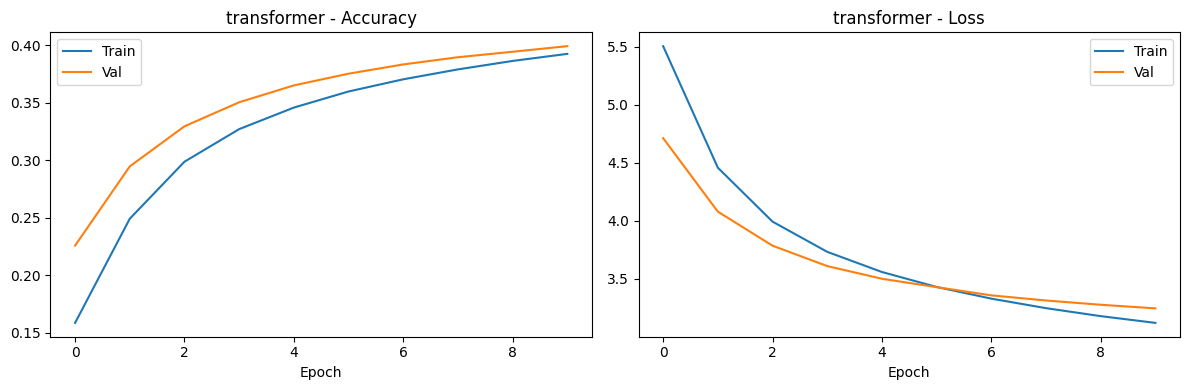

In [12]:
for name, his in hist.items():
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(his.history["masked_accuracy"])
    plt.plot(his.history["val_masked_accuracy"])
    plt.title(f"{name} - Accuracy")
    plt.xlabel("Epoch"); plt.legend(["Train", "Val"])

    plt.subplot(1, 2, 2)
    plt.plot(his.history["loss"])
    plt.plot(his.history["val_loss"])
    plt.title(f"{name} - Loss")
    plt.xlabel("Epoch"); plt.legend(["Train", "Val"])

    plt.tight_layout()
    plt.savefig(f"{name}_model.png", dpi=150)
    plt.savefig(f"{name}_model.jpeg", dpi=150)
    plt.show()

### Test model

In [13]:
test_loss, test_acc = model.evaluate(test_ds, verbose=1)
perplexity = math.exp(test_loss)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f} | Perplexity: {perplexity:.2f}")

704/704 ━━━━━━━━━━━━━━━━━━━━ 83s 118ms/step - loss: 3.2464 - masked_accuracy: 0.3979
Test loss: 3.2464 | Test accuracy: 0.3979 | Perplexity: 25.70


# Generative

In [14]:
_forward = tf.function(lambda x: model(x, training=False))

def generate_reply(model, tokenizer, prompt, max_new_tokens=100, max_length=MAX_LENGTH,
                   temperature=0.8, top_k=40):
    ids = tokenizer.encode(format_prompt(prompt))
    n_prompt = len(ids)

    for _ in range(max_new_tokens):
        window = ids[-(max_length - 1):]
        pos = len(window) - 1
        x = np.full((1, max_length - 1), tokenizer.pad_token_id, dtype=np.int32)
        x[0, :len(window)] = window

        logits = _forward(tf.constant(x))[0, pos].numpy().astype(np.float64)

        if temperature <= 0:
            next_id = int(np.argmax(logits))
        else:
            logits = logits / temperature
            top = np.argpartition(logits, -top_k)[-top_k:]
            p = np.exp(logits[top] - logits[top].max())
            next_id = int(np.random.choice(top, p=p / p.sum()))

        if next_id == tokenizer.eos_token_id:
            break
        ids.append(next_id)

    return tokenizer.decode(ids[n_prompt:], skip_special_tokens=True).strip()


sample_patient, sample_doctor = test_pairs[0]
print("PATIENT :", sample_patient[:300])
print("MODEL   :", generate_reply(model, tokenizer, sample_patient))
print("DOCTOR  :", sample_doctor[:300])


PATIENT : Good afternoon, I am a single mom with a little boy of 2 and a half. He was diagonsed with Infant asthma when he was 10 months old. However I believe it is caused mainly by Allergy - especially dust and dust mite as he does not generally wheeze or cough. But when there is a change of season he gets 
MODEL   : Hello, Thank you for asking at Chat Doctor. I went through your history and would like to make suggestions for you as follows
DOCTOR  : THE MILK ALLERGY SOMETIMES PERSISTS BEYOND 2 YEARS OF AGE AND SPOIL YOUR WHOLE LIFERS MILK THEORY SUGGESTS CHILD NEEDS MILK ONLY BREAST FOR 2 YEARS AND AFTER THAT AGE NO NEED OF MILKWEED WE ADD MILK AND DIARY PROTEINS THESE ARE ANIMAL PROTEINS AND ANIMAL PROTEINS ARE NOT COMPATIBLE WITH HUMAN PROTEI


Test Generative

In [15]:
prompt = "I have headache . what should i do ?"

reply = generate_reply(model, tokenizer, prompt)
print(f"\n\nPROMPT: {prompt}")
print(f"AI: {reply}")



PROMPT: I have headache . what should i do ?
AI: Hi, Thanks for writing to Chat Doctor. I am Chat Doctor. It is unusual to have headache with headache, and headache. You are suffering from severe headache from migraine. In my opinion your symptoms is more likely due to nerve disorder. You should consult an ENT surgeon and get investigated thoroughly examined and investigated. Investigations include x-ray of lumbosacral region might be needed to rule out the above conditions like - routine blood count, thyroid profile and vestibular function test etc. A


In [16]:
eval_pairs  = test_pairs[:NUM_EVAL]
references  = [o for _, o in eval_pairs]
predictions = [generate_reply(model, tokenizer, p) or " " for p, _ in eval_pairs]

scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)
all_scores = [scorer.score(ref, pred) for ref, pred in zip(references, predictions)]
for k in ["rouge1", "rouge2", "rougeL"]:
    print(f"{k}: F1 = {np.mean([s[k].fmeasure for s in all_scores]):.4f}")

rouge1: F1 = 0.2724
rouge2: F1 = 0.0499
rougeL: F1 = 0.1590


In [17]:
P, R, F1 = bert_score_fn(predictions, references, lang="en", verbose=False)
print(f"BERTScore  P={P.mean():.4f}  R={R.mean():.4f}  F1={F1.mean():.4f}")

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERTScore  P=0.8452  R=0.8346  F1=0.8397


In [ ]:
SAVE_DIR = "/content/drive/MyDrive/MedicalChatbot"

os.makedirs(SAVE_DIR, exist_ok=True)


model.save(os.path.join(SAVE_DIR, "medical_transformer.keras"))

tokenizer.save_pretrained(
    os.path.join(SAVE_DIR, "tokenizer")
)

config = {
    "NUM_SAMPLES": NUM_SAMPLES,
    "MAX_LENGTH": MAX_LENGTH,
    "DMODEL": DMODEL,
    "NUM_HEADS": NUM_HEADS,
    "FF_DIM": FF_DIM,
    "NUM_LAYERS": NUM_LAYERS,
    "DROPOUT": DROPOUT,
    "PAD_LABEL": PAD_LABEL
}

with open(
    os.path.join(SAVE_DIR, "config.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(config, f, indent=2)

print("Saved files to:", SAVE_DIR)

Saved files to: /content/drive/MyDrive/MedicalChatbot
